In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from glob import glob
import subprocess

In [27]:
!ls /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I*/vamb_coa/umap_vamb.tsv

/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I01_1/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I01_3/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I02_2/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I02_3/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I02_4/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I03_1/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I11_1/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I11_2/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/I12_1/vamb_coa/umap_vamb.tsv


In [28]:
sample = "I11_2"

binning_dir = f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir"
taxo_dir = f"/gpfs/data/mock_lab/will/mosaic_tmp/taxo_tmpdir"
mapping_folder = f"/gpfs/home/qcf21tku/coa_to_ma_mapping"

In [29]:
df_umap_coords = pd.read_csv(f"{binning_dir}/{sample}/vamb_coa/umap_vamb.tsv", sep = '\t')
df_umap_coords['sample'] = df_umap_coords.contig_id.apply(lambda x: x.split('_')[0])
df_umap_coords = df_umap_coords.rename(columns = {"contig_id":"coa_contig_id"})
df_umap_coords.head()

,coa_contig_id,umap_0,umap_1,sample
0,k127_526608,6.556797,-2.194235,k127
1,k127_800440,2.415175,8.174528,k127
2,k127_21065,12.554152,-1.030449,k127
3,k127_547674,9.766915,2.265805,k127
4,k127_105325,6.583708,-1.418072,k127


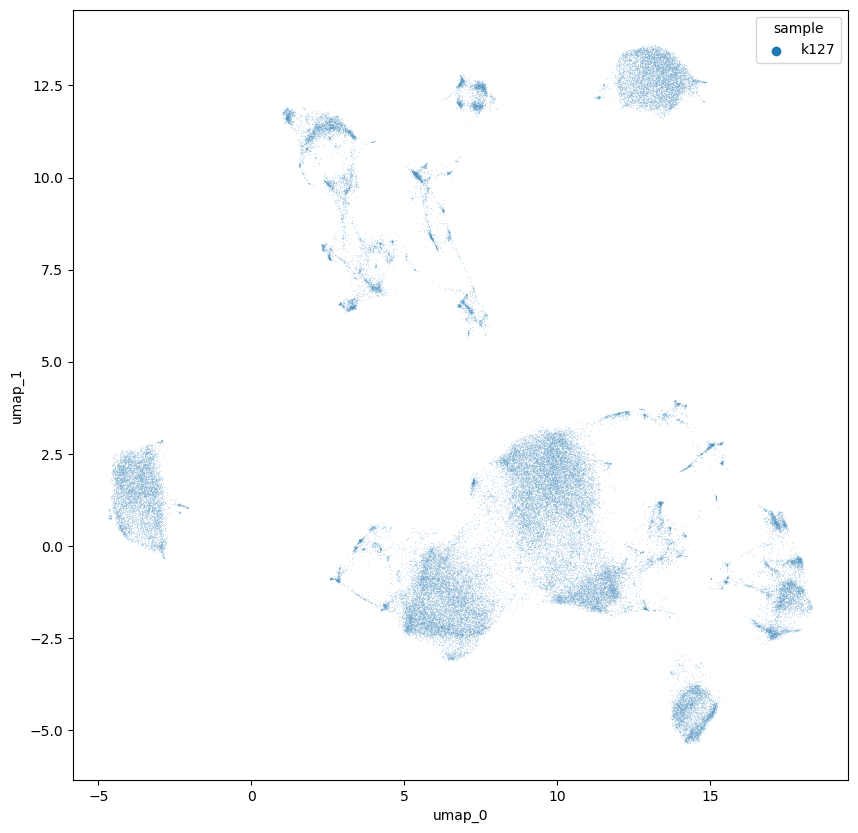

In [30]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df_umap_coords, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'sample',
    alpha = 0.5
)

In [31]:
df_contigs = pd.read_csv(
    f"{mapping_folder}/{sample}.mapping.tsv", 
    sep = '\t', 
    names = ["coa_contig_id", "contig_id", "score"]
)

df_contigs['sample'] = df_contigs.contig_id.apply(lambda x: x.split("_")[0])

df_contigs['score_max'] = df_contigs.groupby('coa_contig_id')['score'].transform(max)

df_contigs = df_contigs[df_contigs.score == df_contigs.score_max]

df_contigs = df_contigs.loc[df_contigs[['coa_contig_id', 'score']].drop_duplicates().index]

df_contigs = df_contigs.drop(columns = ["score", "score_max"])

In [32]:
# (anvio) minimap2 -x asm20 

In [57]:
single_samples = list(set(df_contigs['sample']))

def make_taxo_df(sample_id):
    df = pd.read_csv(f"{taxo_dir}/{sample_id}/{sample_id}.faa.mms2lca", sep = '\t')
    df['sample'] = sample_id
    df['contig_id'] = df['sample'] + '_' + df['contig_id']
    return df

df_taxo = pd.concat(
    make_taxo_df(s) for s in single_samples
)

df = pd.merge(
    df_contigs, 
    df_taxo, 
    on = ['contig_id', 'sample'],
    how = 'left'
).fillna("Unknown")


favourite_groups = [
    "Bacillariophyta", 
    "Nucleocytoviricota", 
    "Mamiellophyceae",
    "Dinophyceae",
    "Metazoa",
    "Cryptophyceae",
    "Haptophyta", 
    "Chlorophyta", 
    "Euglenozoa",
    "Ciliophora",
    "Labyrinthulomycetes", 
    "Chrysophyceae", 
    "Choanoflagellata", 
    "Microbotryomycetes", 
    "Amoebozoa", 
    "Ochrophyta", 
    "Chytridiomycota"
]


def simplify_name(row):
    if row.superkingdom in ["Bacteria", "Archaea"]:
        return "Prokaryota"
    
    if row.superkingdom == "Unknown":
        if row['name'] == "Viruses":
            return "Viruses"
        return "Unknown"
    
    for x in favourite_groups:
        if x in row.lineage:
            return x

    if row.superkingdom == "Virus":
        return "Viruses"
    
    return row.superkingdom
    
    
df['name_simple'] = df.apply(simplify_name, axis = 1)

df['euk_unk'] = df.name_simple.isin(["Unknown", "Eukaryota"])

In [58]:
df = pd.merge(
    df_umap_coords, 
    df, 
    on = 'coa_contig_id', 
    how = 'left'
).fillna("None")

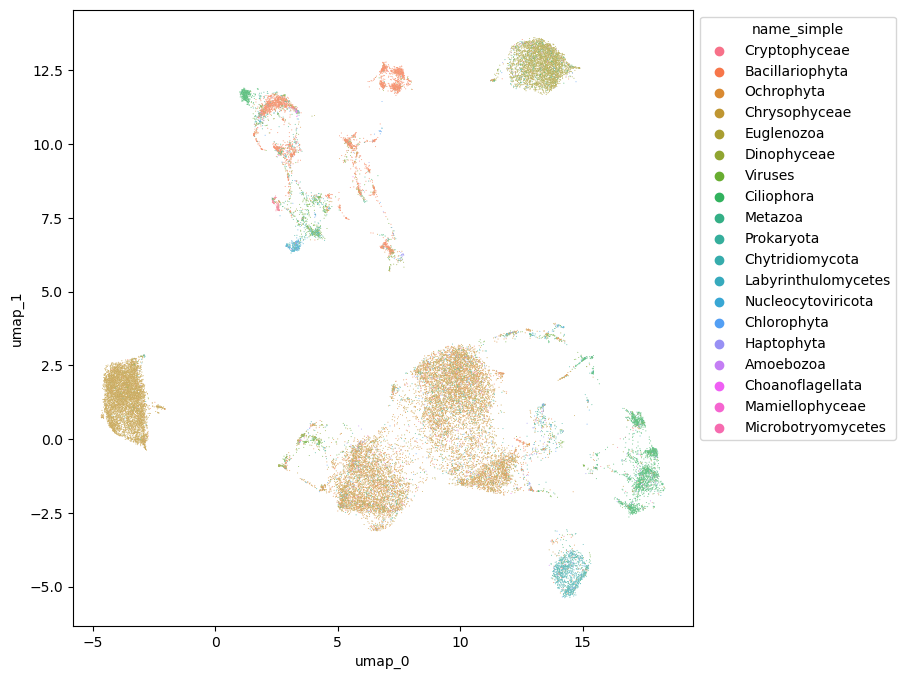

In [59]:
plt.figure(figsize = (8, 8))
ax = sns.scatterplot(
    data = df[~df.name_simple.isin(["Unknown", "Eukaryota", "None"])],
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.5, 
    hue = 'name_simple',
    alpha = 0.85
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [ ]:
mbins = pd.DataFrame([x.split("\t") for x in subprocess.run(
    f"grep -H '>' {binning_dir}/{sample}/metabat_coa/*.fa | cut -f 10 -d '/' | sed 's|.fa:>|\t|g'", 
    capture_output = True, 
    shell = True
).stdout.decode("ASCII").strip().split("\n")], columns = ["metabat_id", "coa_contig_id"])

df = pd.merge(
    df, 
    mbins, 
    on = 'coa_contig_id', 
    how = 'left'
).fillna("None")

vbins = pd.DataFrame([x.split("\t") for x in subprocess.run(
    f"grep -H '>' {binning_dir}/{sample}/vamb_coa/*bins/*.fna | cut -f 1 -d ' ' | cut -f 11 -d '/' | sed 's|.fna:>|\t|g'", 
    capture_output = True, 
    shell = True
).stdout.decode("ASCII").strip().split("\n")], columns = ["vamb_id", "coa_contig_id"])

df = pd.merge(
    df, 
    vbins, 
    on = 'coa_contig_id', 
    how = 'left'
).fillna("None")

df.head()

In [ ]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'metabat_id',
    alpha = 0.5
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [ ]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'vamb_id',
    alpha = 0.5
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [ ]:
#Below here is done on a per-sample basis... Don't rerun!
